# Chapitre 9 - Exercices 9.1 à 9.5

Ce notebook traite les premiers exercices du chapitre 9, consacrés à la
linéarisabilité :

- **9.1** : linéarisable ou pas ? Quatre historiques à juger (raisonnement) ;
- **9.2** : le coût d'un vérificateur de linéarisabilité, avec et sans mémoïsation
  (mini-lab) ;
- **9.3** : quorums, délais variables et réparation synchrone (mini-lab et calcul) ;
- **9.4** : placer le leader d'une base linéarisable répartie sur trois centres de
  données (calcul) ;
- **9.5** : linéarisable, sérialisable ou causal ? Et la course entre une notification
  et la réplication (raisonnement et calcul).

In [1]:
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.consistency import Op
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 9.1 : linéarisable ou pas ?

**Énoncé.** Un registre $x$ vaut initialement 0. Pour chacun des quatre historiques
suivants (intervalles [appel, réponse] en millisecondes), dire s'il est linéarisable ; si
oui, donner un ordre de linéarisation, sinon expliquer pourquoi aucun n'existe.

- **(a)** A : `write(1)` [0, 4] ; B : `write(2)` [1, 3] ; C : `read → 2` [5, 6] ; C : `read → 1` [7, 8].
- **(b)** A : `cas(0 → 1) ok` [0, 2] ; B : `cas(0 → 2) ok` [1, 3].
- **(c)** A : `write(1)` [0, ∞[ sans réponse (délai expiré) ; B : `read → 0` [2, 3] ; C : `read → 1` [4, 5].
- **(d)** A : `write(1)` [0, 1] ; B : `read → 0` [0,5 ; 3] ; C : `read → 1` [2 ; 2,5].

Vérifier ensuite les réponses avec `cs.check_linearizable`.

**Rappels.** Définition par points de linéarisation, lectures concurrentes d'une écriture,
opérations sans réponse (cours 1, section 2 ; section *What Makes a System Linearizable?*).

**Solution.**

- **(a) Non.** Les deux écritures sont terminées à $t = 4$, avant les deux lectures de C,
  qui sont séquentielles. Après les deux écritures, la valeur est fixée (1 ou 2 selon
  l'ordre des points) et plus personne n'écrit : deux lectures successives ne peuvent pas
  renvoyer 2 puis 1.
- **(b) Non.** Les deux CAS attendent 0 et réussissent. Quel que soit l'ordre, le second
  trouve la valeur écrite par le premier (1 ou 2), pas 0 : il devrait échouer.
- **(c) Oui.** Une écriture sans réponse a pu prendre effet à n'importe quel instant après
  son appel (ou jamais). Ordre : lecture de B (0), puis l'écriture de A, placée après le
  point de B et avant 5, puis la lecture de C (1).
- **(d) Oui, et c'est le piège.** B lit 0 alors que l'écriture de 1 est **terminée** avant
  la fin de B, et que C a même lu 1 **pendant** la lecture de B. Mais B a commencé à 0,5,
  avant la fin de l'écriture : on place par exemple le point de B à 0,55, celui de
  l'écriture à 0,7, et celui de C à 2,2 (le vérificateur choisit 0,88 pour les deux
  premiers, B passant en premier). Les lectures concurrentes ont droit à l'ancienne valeur tant que leur
  point peut précéder celui de l'écriture.

,historique,linéarisable,ordre
0,(a),False,-
1,(b),False,-
2,(c),True,B:r→0@2.15 ; A:w(1)@2.15 ; C:r→1@4.15
3,(d),True,B:r→0@0.88 ; A:w(1)@0.88 ; C:r→1@2.08


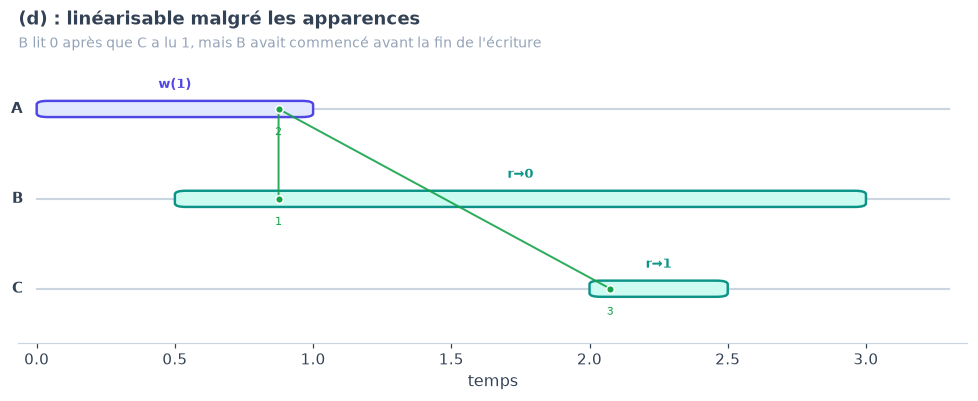

In [2]:
cas_ex = {
    "(a)": [Op("A", "write", 1, "ok", 0, 4), Op("B", "write", 2, "ok", 1, 3), Op("C", "read", None, 2, 5, 6),
            Op("C", "read", None, 1, 7, 8)],
    "(b)": [Op("A", "cas", (0, 1), True, 0, 2), Op("B", "cas", (0, 2), True, 1, 3)],
    "(c)": [Op("A", "write", 1, None, 0, done=False), Op("B", "read", None, 0, 2, 3), Op("C", "read", None, 1, 4, 5)],
    "(d)": [Op("A", "write", 1, "ok", 0, 1), Op("B", "read", None, 0, 0.5, 3), Op("C", "read", None, 1, 2, 2.5)],
}
rows = []
for k, h in cas_ex.items():
    r = cs.check_linearizable(h)
    rows.append(dict(historique=k, linéarisable=r.ok,
                     ordre=" ; ".join(f"{h[i].client}:{cs.op_label(h[i])}@{p:.2f}" for i, p in zip(r.order, r.points)) if r.ok else "-"))
display(pd.DataFrame(rows))
r = cs.check_linearizable(cas_ex["(d)"])
st = cs.plot_history(cas_ex["(d)"], title="(d) : linéarisable malgré les apparences",
                     subtitle="B lit 0 après que C a lu 1, mais B avait commencé avant la fin de l'écriture",
                     result=r, clients=["A", "B", "C"], t_max=3.3, width=9)
st.show()

Le vérificateur confirme (a) et (b) non linéarisables, (c) et (d) linéarisables. Dans (d),
l'ordre trouvé place la lecture de B **avant** l'écriture : le fait que B **réponde** tard
n'oblige pas son point à être tardif.

> **À retenir.** Juger la linéarisabilité, c'est chercher des points dans les
> intervalles. Une opération longue ou sans réponse offre beaucoup de latitude ; une
> opération **terminée** avant le début d'une autre la précède forcément.

## Exercice 9.2 : le coût d'un vérificateur de linéarisabilité

**Énoncé.** Vérifier la linéarisabilité est NP-complet en général. On veut mesurer ce que
coûte la recherche en pratique.

1. Écrire un générateur d'historiques **linéarisables** de $n$ opérations réparties sur
   $k$ clients (chaque client enchaîne ses opérations ; les durées sont aléatoires, et les
   résultats des lectures sont calculés à partir de points de linéarisation tirés au
   hasard). En faire une version **non linéarisable** en corrompant la dernière lecture.
2. Écrire une recherche **sans mémoïsation** (on essaie tous les ordres compatibles avec le
   temps réel) et comparer le nombre d'états explorés à celui de `cs.check_linearizable`.
3. Comment évolue le coût avec la concurrence (nombre de clients) ? Pourquoi la version
   non linéarisable est-elle la plus chère ?

**Rappels.** Algorithme de Wing et Gong, mémoïsation de Lowe (cours 1, section 2) ;
section *What Makes a System Linearizable?* (test de linéarisabilité par enregistrement des
requêtes et réponses).

**Solution.**

*1.* Chaque client exécute ses opérations l'une après l'autre ; on tire pour chaque
opération un intervalle, puis un point dans l'intervalle ; en rejouant les opérations dans
l'ordre des points sur un registre, on obtient les résultats des lectures : l'historique
est linéarisable par construction.

*2.* Sans mémoïsation, deux préfixes différents qui mènent au même ensemble d'opérations
placées et à la même valeur sont explorés deux fois ; avec beaucoup d'opérations
concurrentes, le nombre d'ordres croît comme une factorielle.

*3.* Une recherche qui **réussit** s'arrête au premier ordre valide ; une recherche qui
**échoue** doit prouver qu'aucun ordre n'existe, donc tout explorer : c'est le pire cas.

historiques générés linéarisables : True ; corrompus rejetés : True


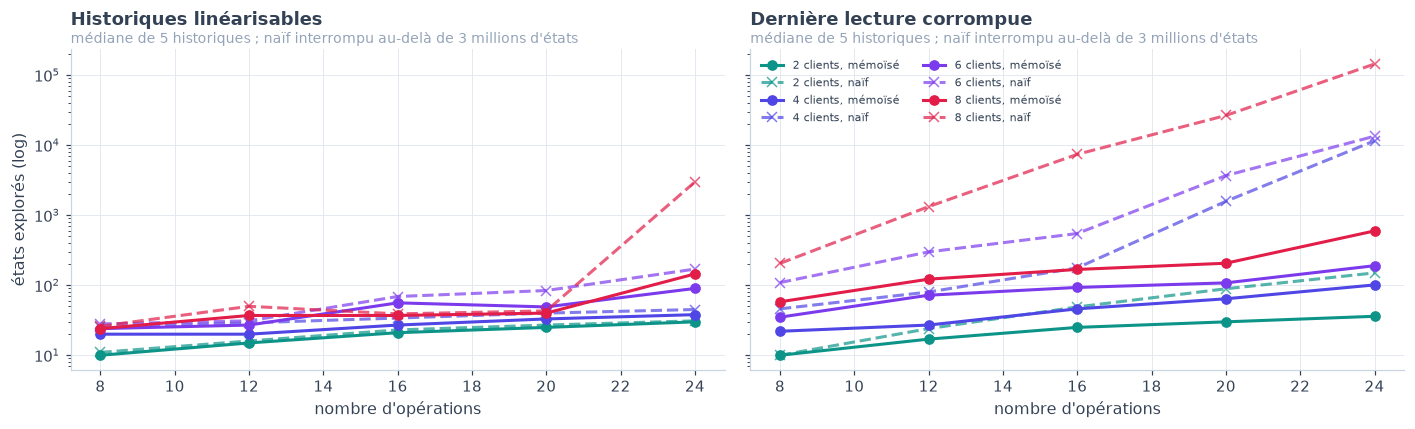

memo     naif
corrompu clients               
False    2          33       34
         4          71      320
         6         158      282
         8         312    18727
True     2          42      422
         4         108    24002
         6         358    66541
         8        1147  1348102

In [3]:
def historique_aleatoire(n, k, seed, corrompre=False):
    g = np.random.default_rng(seed)
    t = np.zeros(k)
    ops = []
    for i in range(n):
        c = int(g.integers(k))
        t0 = t[c] + g.exponential(0.3)
        t1 = t0 + g.exponential(2.0)
        t[c] = t1
        kind = "write" if g.random() < 0.4 else "read"
        ops.append(dict(client=f"c{c}", kind=kind, t0=t0, t1=t1, p=g.uniform(t0, t1), v=i + 1))
    val, hist = 0, []
    for o in sorted(ops, key=lambda o: o["p"]):
        if o["kind"] == "write":
            val = o["v"]
            hist.append(Op(o["client"], "write", o["v"], "ok", o["t0"], o["t1"]))
        else:
            hist.append(Op(o["client"], "read", None, val, o["t0"], o["t1"]))
    if corrompre:
        last = max((i for i, o in enumerate(hist) if o.kind == "read"), key=lambda i: hist[i].t_call)
        hist[last].result = -1
    return sorted(hist, key=lambda o: o.t_call)

def check_sans_memo(history, init=0, limite=3_000_000):
    ops = list(history); n = len(ops); explores = [0]
    def dfs(mask, state):
        explores[0] += 1
        if explores[0] > limite:
            raise RuntimeError
        if mask == (1 << n) - 1:
            return True
        min_ret = min(ops[i].t_return for i in range(n) if not mask >> i & 1)
        for i in range(n):
            if mask >> i & 1 or ops[i].t_call > min_ret:
                continue
            ok, s2 = cs.register_step(state, ops[i])
            if ok and dfs(mask | 1 << i, s2):
                return True
        return False
    return dfs(0, init), explores[0]

rows = []
for k in (2, 4, 6, 8):
    for n in (8, 12, 16, 20, 24):
        for corr in (False, True):
            for seed in range(5):
                h = historique_aleatoire(n, k, seed, corr)
                memo = cs.check_linearizable(h)
                try:
                    _, naive = check_sans_memo(h)
                except RuntimeError:
                    naive = np.nan
                rows.append(dict(clients=k, n=n, corrompu=corr, ok=memo.ok, memo=memo.explored, naif=naive))
X = pd.DataFrame(rows)
print("historiques générés linéarisables :", X[~X.corrompu].ok.all(), "; corrompus rejetés :", (~X[X.corrompu].ok).all())
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, corr in zip(axes, (False, True)):
    g = X[X.corrompu == corr].groupby(["clients", "n"])[["memo", "naif"]].median().reset_index()
    for k, c in zip((2, 4, 6, 8), (TEAL, INDIGO, VIOLET, ROSE)):
        s_ = g[g.clients == k]
        ax.plot(s_.n, s_.memo, "o-", color=c, label=f"{k} clients, mémoïsé")
        ax.plot(s_.n, s_.naif, "x--", color=c, alpha=0.7, label=f"{k} clients, naïf")
    ax.set_yscale("log"); ax.set_xlabel("nombre d'opérations")
    ax.set_title("Historiques linéarisables" if not corr else "Dernière lecture corrompue")
    subtitle(ax, "médiane de 5 historiques ; naïf interrompu au-delà de 3 millions d'états")
axes[0].set_ylabel("états explorés (log)")
axes[1].legend(fontsize=7.5, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()
X.groupby(["corrompu", "clients"])[["memo", "naif"]].max()

Quand l'historique est linéarisable, les deux recherches trouvent vite un ordre (le premier
choix est souvent le bon), sauf quelques cas très concurrents. Quand il ne l'est pas, la
recherche naïve explose avec le nombre de clients concurrents : sa médiane croît
exponentiellement avec le nombre d'opérations, et le pire historique à 8 clients lui coûte
1,3 million d'états, contre un peu plus d'un millier pour la version mémoïsée, qui reste
dans les centaines à milliers d'états : le nombre d'**ensembles**
d'opérations placées compatibles avec le temps réel reste limité si peu d'opérations sont
concurrentes à la fois. C'est pourquoi les outils comme Knossos ou Porcupine travaillent
sur des historiques courts, découpés par clé.

> **À retenir.** Tester la linéarisabilité coûte cher dans le pire cas (un historique
> fautif oblige à tout explorer), d'autant plus que la concurrence est forte ; la
> mémoïsation des états (opérations placées, valeur) rend le test praticable.